In [1]:
import pandas as pd

df = pd.read_csv("../data/listings.csv.gz")
print(df.shape)
df.head()

(27232, 90)


,id,listing_url,scrape_id,last_scraped,source,name,description,neighborhood_overview,picture_url,host_id,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,25436,https://www.airbnb.com/rooms/25436,20260925130056,2026-09-28,previous scrape,In the forest Sea view Two minutes to the city.,Our house is in Bebek Koru. If you want villag...,NaN,https://a0.muscache.com/pictures/b64c3ef0-2256...,105823,...,NaN,NaN,NaN,NaN,NaN,1,1,0,0,NaN
1,34177,https://www.airbnb.com/rooms/34177,20260925130056,2026-09-28,previous scrape,PETIT HOUSE,My petit house is located in the bosphorous an...,NaN,https://a0.muscache.com/pictures/47356451/c288...,147330,...,4.81,4.69,4.81,NaN,NaN,2,2,0,0,0.12
2,42835,https://www.airbnb.com/rooms/42835,20260925130056,2026-09-28,previous scrape,Cozy apartment in the heart of Istanbul,Welcome to our cozy 2-bedroom apartment locate...,NaN,https://a0.muscache.com/pictures/miso/Hosting-...,187026,...,NaN,NaN,NaN,NaN,NaN,3,1,2,0,NaN
3,73477,https://www.airbnb.com/rooms/73477,20260925130056,2026-09-28,previous scrape,Sea View Apartment in Taksim/ Center of Istanbul,Sea View Apartment in Taksim/ Center of Istanbul,NaN,https://a0.muscache.com/pictures/409813ff-21c0...,383789,...,5.00,5.00,4.91,NaN,NaN,1,1,0,0,0.20
4,77292,https://www.airbnb.com/rooms/77292,20260925130056,2026-09-28,NaN,Sea View 3BR Apartment with Terrace in Taksim,Enjoy a comfortable stay in this spacious 3-be...,NaN,https://a0.muscache.com/pictures/b2ded642-2b75...,414003,...,4.78,4.72,4.33,34-554,NaN,12,9,3,0,0.24


In [2]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 27232 entries, 0 to 27231
Data columns (total 90 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            27232 non-null  int64  
 1   listing_url                                   27232 non-null  str    
 2   scrape_id                                     27232 non-null  int64  
 3   last_scraped                                  27232 non-null  str    
 4   source                                        10669 non-null  str    
 5   name                                          27232 non-null  str    
 6   description                                   27070 non-null  str    
 7   neighborhood_overview                         0 non-null      float64
 8   picture_url                                   27232 non-null  str    
 9   host_id                                       27232 non-null  int64  
 1

In [3]:
df[["price", "price_quote_price_per_night", "estimated_revenue_l365d"]].head(10)

,price,price_quote_price_per_night,estimated_revenue_l365d
0,NaN,NaN,NaN
1,"$4,736.32",4736.32,0.0
2,NaN,NaN,NaN
3,"$1,501.51",1501.51,0.0
4,"$11,860.00",11860.00,284640.0
5,"$3,884.60",3884.60,0.0
6,"$4,668.27",4668.27,0.0
7,"$6,302.00",6302.00,151248.0
8,"$2,106.69",2106.69,0.0
9,"$2,330.00",2330.00,13980.0


In [4]:
df["price"].describe()

count         24553
unique        13011
top       $3,000.00
freq            127
Name: price, dtype: object

In [5]:
df["price_clean"] = (
    df["price"]
    .str.replace("$", "", regex=False)
    .str.replace(",", "", regex=False)
    .astype(float)
)

print((df["price_clean"] - df["price_quote_price_per_night"]).abs().max())

0.0


In [6]:
df["price_clean"].describe()

count    2.455300e+04
mean     6.022492e+03
std      3.823967e+04
min      7.855000e+01
25%      2.303000e+03
50%      3.710000e+03
75%      6.075000e+03
max      4.989148e+06
Name: price_clean, dtype: float64

In [7]:
df["price_clean"].quantile([0.01, 0.05, 0.5, 0.95, 0.99])

0.01      417.2800
0.05      834.5500
0.50     3710.0000
0.95    13932.5680
0.99    38317.8036
Name: price_clean, dtype: float64

In [8]:
low, high = df["price_clean"].quantile([0.01, 0.99])
print(f"Keeping prices between {low:.0f} and {high:.0f}")

df_clean = df[df["price_clean"].between(low, high)].copy()
print("Before:", len(df), "After:", len(df_clean))

Keeping prices between 417 and 38318
Before: 27232 After: 24065


In [9]:
df_clean["price_clean"].describe()

count    24065.000000
mean      4895.803193
std       4291.077757
min        417.280000
25%       2335.000000
50%       3707.800000
75%       6008.330000
max      38286.330000
Name: price_clean, dtype: float64

In [10]:
keep_cols = [
    "id", "name", "neighbourhood_cleansed", "latitude", "longitude",
    "property_type", "room_type", "accommodates", "bedrooms", "beds",
    "bathrooms_text", "price_clean", "minimum_nights", "availability_365",
    "number_of_reviews", "review_scores_rating", "reviews_per_month",
    "host_id", "host_is_superhost", "calculated_host_listings_count",
    "estimated_occupancy_l365d", "estimated_revenue_l365d",
]

df_clean = df_clean[keep_cols].copy()
print(df_clean.shape)

(24065, 22)


In [11]:
df_clean.to_csv("../data/listings_clean.csv", index=False)

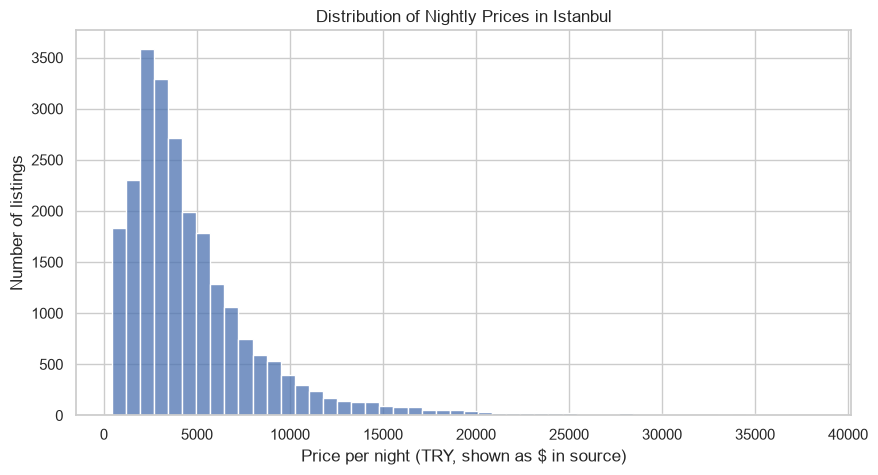

In [12]:
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")

plt.figure(figsize=(10, 5))
sns.histplot(df_clean["price_clean"], bins=50)
plt.title("Distribution of Nightly Prices in Istanbul")
plt.xlabel("Price per night (TRY, shown as $ in source)")
plt.ylabel("Number of listings")
plt.savefig("../images/price_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

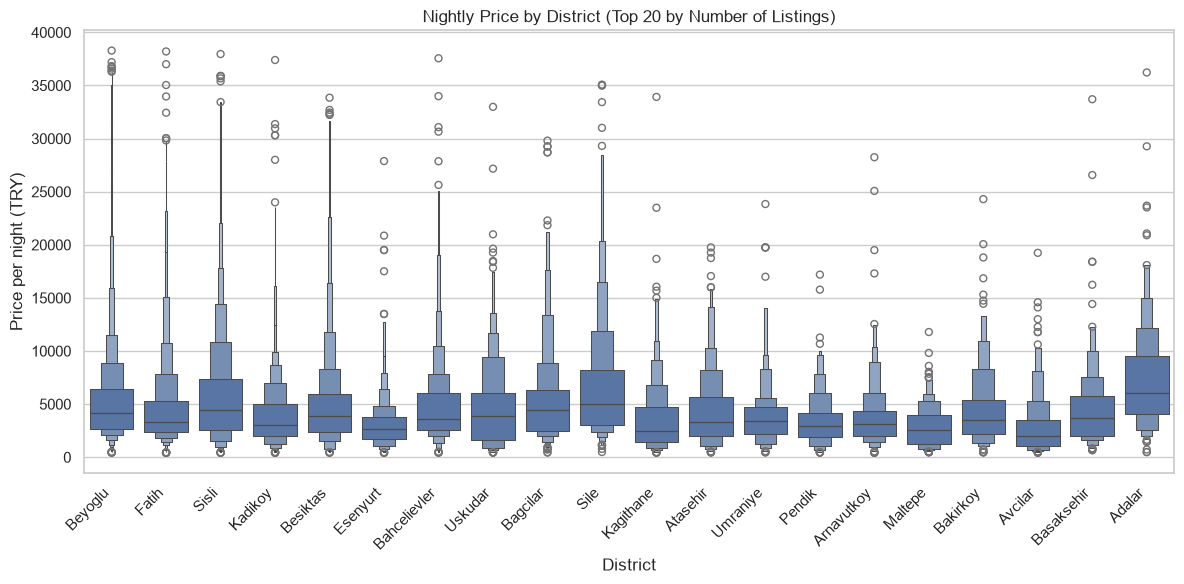

In [13]:
top_districts = df_clean["neighbourhood_cleansed"].value_counts().head(20).index

plt.figure(figsize=(12, 6))
sns.boxenplot(
    data=df_clean[df_clean["neighbourhood_cleansed"].isin(top_districts)],
    x="neighbourhood_cleansed",
    y="price_clean",
    order=top_districts,
)
plt.xticks(rotation=45, ha="right")
plt.title("Nightly Price by District (Top 20 by Number of Listings)")
plt.xlabel("District")
plt.ylabel("Price per night (TRY)")
plt.tight_layout()
plt.savefig("../images/district_boxplot.png", dpi=150, bbox_inches="tight")
plt.show()

In [14]:
district_stats = (
    df_clean[df_clean["neighbourhood_cleansed"].isin(top_districts)]
    .groupby("neighbourhood_cleansed")["price_clean"]
    .agg(["count", "median"])
    .sort_values("count", ascending=False)
)
district_stats

,count,median
neighbourhood_cleansed,,
Beyoglu,6852,4201.355
Fatih,3807,3361.000
Sisli,3280,4459.000
Kadikoy,1691,3042.120
Besiktas,1270,3882.710
Esenyurt,823,2667.530
Bahcelievler,713,3612.500
Uskudar,482,3875.405
Bagcilar,421,4457.830


In [15]:
district_stats = (
    df_clean[df_clean["neighbourhood_cleansed"].isin(top_districts)]
    .groupby("neighbourhood_cleansed")["price_clean"]
    .agg(["count", "median"])
    .sort_values("median", ascending=False)
)
district_stats

,count,median
neighbourhood_cleansed,,
Adalar,212,6000.000
Sile,368,5000.000
Sisli,3280,4459.000
Bagcilar,421,4457.830
Beyoglu,6852,4201.355
Besiktas,1270,3882.710
Uskudar,482,3875.405
Basaksehir,221,3666.870
Bahcelievler,713,3612.500


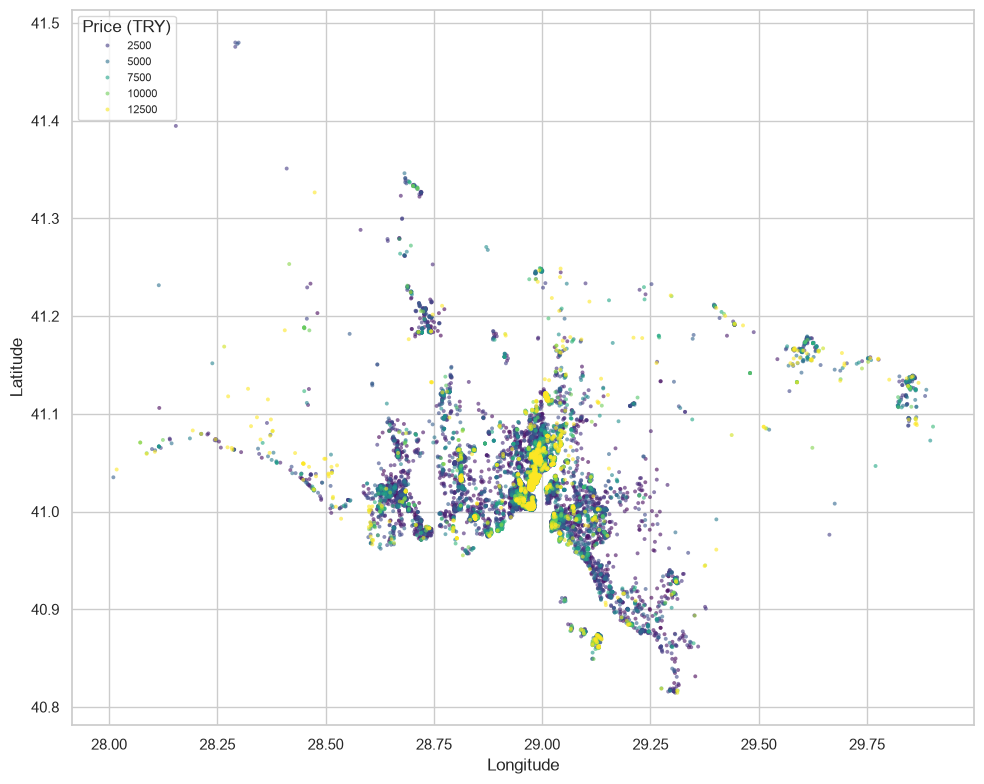

In [16]:
plot_df = df_clean.sort_values("price_clean")

plt.figure(figsize=(10, 8))
sns.scatterplot(
    data=plot_df,
    x="longitude",
    y="latitude",
    hue=plot_df["price_clean"].clip(upper=plot_df["price_clean"].quantile(0.95)),
    palette="viridis",
    s=8,
    alpha=0.6,
    linewidth=0,
)
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.legend(title="Price (TRY)", loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [17]:
import geopandas as gpd

gdf = gpd.read_file("../data/neighbourhoods.geojson")
print(gdf.head())

  neighbourhood neighbourhood_group  \
0          Sile                None   
1       Catalca                None   
2          Eyup                None   
3       Sariyer                None   
4    Arnavutkoy                None   

                                            geometry  
0  MULTIPOLYGON (((29.40012 41.08268, 29.40108 41...  
1  MULTIPOLYGON (((28.53621 41.10618, 28.53192 41...  
2  MULTIPOLYGON (((28.94888 41.26316, 28.94768 41...  
3  MULTIPOLYGON (((29.05436 41.08138, 29.05444 41...  
4  MULTIPOLYGON (((28.81857 41.13622, 28.80993 41...  


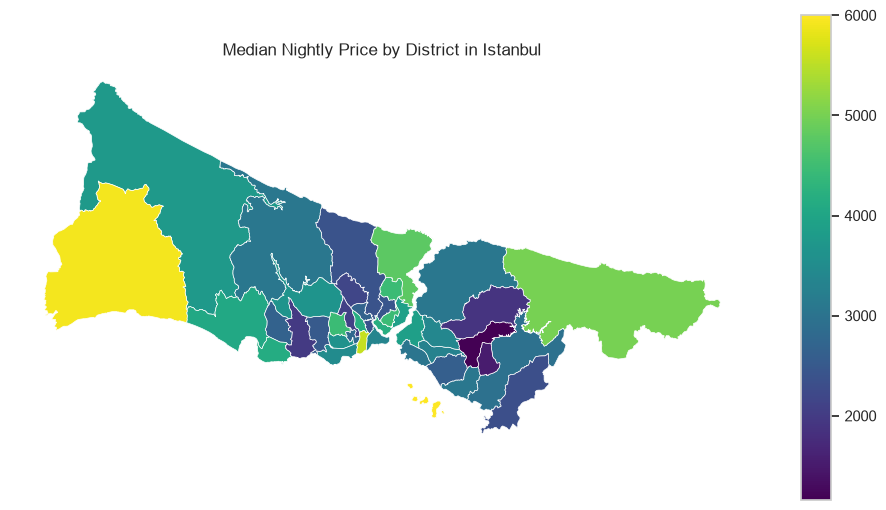

In [18]:
medians = (
    df_clean.groupby("neighbourhood_cleansed")["price_clean"]
    .median()
    .reset_index()
)
gdf = gdf.merge(
    medians,
    left_on="neighbourhood",
    right_on="neighbourhood_cleansed",
    how="left",
)

fig, ax = plt.subplots(figsize=(12, 8))
gdf.plot(
    column="price_clean",
    cmap="viridis",
    legend=True,
    ax=ax,
    missing_kwds={"color": "lightgrey"},
    edgecolor="white",
    linewidth=0.5,
)
ax.set_title("Median Nightly Price by District in Istanbul")
ax.axis("off")
plt.savefig("../images/district_map.png", dpi=150, bbox_inches="tight")
plt.show()